In [1]:
# 1. Import necessary packages and change working directory
import pandas as pd
import numpy as np
import os

# Set working directory where your dataset is located
r = r'C:\DGA_04.08.2025-LSTM'  # use raw string or double backslashes to avoid escape errors
os.chdir(r)




In [2]:
import matplotlib.pyplot as plt

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, Bidirectional
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.utils import to_categorical





In [3]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, roc_curve
)
from collections import Counter

In [4]:
# 1. Set working directory where your dataset is located
r = r'C:\DGA_04.08.2025-LSTM'  # <- your provided path
os.chdir(r)

# 2. Load dataset
# Expecting a CSV/text file with columns: label, origin, domain
# Example: "dga-dataset.txt" as in prior conversations
df = pd.read_csv('dga-dataset.txt', header=None, names=['label', 'origin', 'domain'])
print(f"Loaded {len(df)} rows. Label distribution:\n{df['label'].value_counts()}")

Loaded 674898 rows. Label distribution:
label
dga      337500
legit    337398
Name: count, dtype: int64


In [5]:
# 3. Basic cleaning / preprocessing
df = df.dropna(subset=['domain', 'label']).copy()
df['domain'] = df['domain'].astype(str).str.strip().str.lower()

# If label is not binary (e.g., 'dga'/'benign'), convert to 0/1 accordingly
# Adjust mapping if your dataset uses different labels
label_vals = df['label'].unique()
print("Unique labels:", label_vals)
if set(label_vals) <= set(['0', '1']) or set(label_vals) <= set([0,1]):
    df['y'] = df['label'].astype(int)
else:
    # common: benign / dga or 'benign' and 'dga'
    df['y'] = df['label'].map(lambda x: 1 if str(x).lower() in ('dga','malicious','1','true') else 0)

Unique labels: ['dga' 'legit']


In [6]:
# 4. Character-level tokenizer and sequence preparation
max_chars = 80  # maximum domain length to keep (pad/truncate)
tokenizer = Tokenizer(char_level=True, lower=True, filters=None)  # keep punctuation like '-' etc.
tokenizer.fit_on_texts(df['domain'].tolist())

sequences = tokenizer.texts_to_sequences(df['domain'].tolist())
X = pad_sequences(sequences, maxlen=max_chars, padding='post', truncating='post')
y = df['y'].values

vocab_size = len(tokenizer.word_index) + 1
print(f"Vocab size (chars): {vocab_size}, X shape: {X.shape}")

Vocab size (chars): 40, X shape: (674898, 80)


In [7]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SpatialDropout1D, Bidirectional, LSTM, Dropout, Dense, BatchNormalization, GlobalMaxPooling1D
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.metrics import AUC
from tensorflow.keras.losses import BinaryCrossentropy
from sklearn.model_selection import train_test_split
from collections import Counter

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Compute class weights
counter = Counter(y_train)
total = sum(counter.values())
class_weight = {cls: total / (len(counter) * count) for cls, count in counter.items()}
print("Class distribution (train):", counter)
print("Using class_weight:", class_weight)

# Improved LSTM model with SpatialDropout1D and label smoothing
embedding_dim = 64
lstm_units = 48
dropout_rate = 0.5

model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=embedding_dim, input_length=max_chars),
    SpatialDropout1D(0.3),  # drop some embedding channels
    Bidirectional(LSTM(lstm_units, return_sequences=True, dropout=0.4, recurrent_dropout=0.3)),
    Bidirectional(LSTM(lstm_units//2, return_sequences=True, dropout=0.3, recurrent_dropout=0.2)),
    GlobalMaxPooling1D(),
    BatchNormalization(),
    Dense(64, activation='relu'),
    Dropout(dropout_rate),
    BatchNormalization(),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

# Use label smoothing in binary crossentropy
loss_fn = BinaryCrossentropy(label_smoothing=0.05)

model.compile(
    optimizer='adam',
    loss=loss_fn,
    metrics=['accuracy', AUC(name='auc')]
)

model.summary()

# Callbacks
es = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
ckpt = ModelCheckpoint('best_lstm_dga_v3.h5', monitor='val_loss', save_best_only=True)
rlr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3)



Class distribution (train): Counter({1: 270000, 0: 269918})
Using class_weight: {0: 1.0001518979838322, 1: 0.9998481481481482}


c:\Users\SİNAN\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ ?                      │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ ?                      │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ ?                      │   0 (unbuilt) │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ ?                      │   0 (unbuilt) │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [8]:
# Train
history = model.fit(
    X_train, y_train,
    validation_split=0.1,
    epochs=10,
    batch_size=128,
    callbacks=[es, ckpt, rlr],
    class_weight=class_weight,
    verbose=1
)


Epoch 1/10
3797/3797 ━━━━━━━━━━━━━━━━━━━━ 0s 861ms/step - accuracy: 0.7828 - auc: 0.8534 - loss: 0.4867

3797/3797 ━━━━━━━━━━━━━━━━━━━━ 3325s 873ms/step - accuracy: 0.7828 - auc: 0.8534 - loss: 0.4867 - val_accuracy: 0.8835 - val_auc: 0.9529 - val_loss: 0.3317 - learning_rate: 0.0010
Epoch 2/10
3797/3797 ━━━━━━━━━━━━━━━━━━━━ 0s 813ms/step - accuracy: 0.8752 - auc: 0.9438 - loss: 0.3510

3797/3797 ━━━━━━━━━━━━━━━━━━━━ 3151s 830ms/step - accuracy: 0.8752 - auc: 0.9438 - loss: 0.3510 - val_accuracy: 0.9147 - val_auc: 0.9735 - val_loss: 0.2773 - learning_rate: 0.0010
Epoch 3/10
3797/3797 ━━━━━━━━━━━━━━━━━━━━ 0s 591ms/step - accuracy: 0.9035 - auc: 0.9641 - loss: 0.3036

3797/3797 ━━━━━━━━━━━━━━━━━━━━ 2284s 601ms/step - accuracy: 0.9035 - auc: 0.9641 - loss: 0.3036 - val_accuracy: 0.9349 - val_auc: 0.9841 - val_loss: 0.2408 - learning_rate: 0.0010
Epoch 4/10
3797/3797 ━━━━━━━━━━━━━━━━━━━━ 0s 535ms/step - accuracy: 0.9219 - auc: 0.9739 - loss: 0.2735

3797/3797 ━━━━━━━━━━━━━━━━━━━━ 2076s 547ms/step - accuracy: 0.9219 - auc: 0.9739 - loss: 0.2735 - val_accuracy: 0.9452 - val_auc: 0.9881 - val_loss: 0.2238 - learning_rate: 0.0010
Epoch 5/10
3797/3797 ━━━━━━━━━━━━━━━━━━━━ 0s 559ms/step - accuracy: 0.9316 - auc: 0.9785 - loss: 0.2567

3797/3797 ━━━━━━━━━━━━━━━━━━━━ 2166s 571ms/step - accuracy: 0.9316 - auc: 0.9785 - loss: 0.2567 - val_accuracy: 0.9495 - val_auc: 0.9894 - val_loss: 0.2176 - learning_rate: 0.0010
Epoch 6/10
3797/3797 ━━━━━━━━━━━━━━━━━━━━ 0s 574ms/step - accuracy: 0.9369 - auc: 0.9812 - loss: 0.2464

3797/3797 ━━━━━━━━━━━━━━━━━━━━ 2225s 586ms/step - accuracy: 0.9369 - auc: 0.9812 - loss: 0.2464 - val_accuracy: 0.9536 - val_auc: 0.9905 - val_loss: 0.2115 - learning_rate: 0.0010
Epoch 7/10
3797/3797 ━━━━━━━━━━━━━━━━━━━━ 0s 589ms/step - accuracy: 0.9399 - auc: 0.9827 - loss: 0.2402

3797/3797 ━━━━━━━━━━━━━━━━━━━━ 2284s 601ms/step - accuracy: 0.9399 - auc: 0.9827 - loss: 0.2402 - val_accuracy: 0.9555 - val_auc: 0.9914 - val_loss: 0.2062 - learning_rate: 0.0010
Epoch 8/10
3797/3797 ━━━━━━━━━━━━━━━━━━━━ 0s 607ms/step - accuracy: 0.9432 - auc: 0.9838 - loss: 0.2348

3797/3797 ━━━━━━━━━━━━━━━━━━━━ 2354s 620ms/step - accuracy: 0.9432 - auc: 0.9838 - loss: 0.2348 - val_accuracy: 0.9572 - val_auc: 0.9921 - val_loss: 0.2035 - learning_rate: 0.0010
Epoch 9/10
3797/3797 ━━━━━━━━━━━━━━━━━━━━ 0s 627ms/step - accuracy: 0.9457 - auc: 0.9844 - loss: 0.2313

3797/3797 ━━━━━━━━━━━━━━━━━━━━ 2434s 641ms/step - accuracy: 0.9457 - auc: 0.9844 - loss: 0.2313 - val_accuracy: 0.9603 - val_auc: 0.9929 - val_loss: 0.1975 - learning_rate: 0.0010
Epoch 10/10
3797/3797 ━━━━━━━━━━━━━━━━━━━━ 0s 652ms/step - accuracy: 0.9477 - auc: 0.9854 - loss: 0.2273

3797/3797 ━━━━━━━━━━━━━━━━━━━━ 2531s 667ms/step - accuracy: 0.9477 - auc: 0.9854 - loss: 0.2273 - val_accuracy: 0.9603 - val_auc: 0.9931 - val_loss: 0.1956 - learning_rate: 0.0010


In [9]:
# 9. Evaluate on test set
y_prob = model.predict(X_test, batch_size=512).ravel()
y_pred = (y_prob >= 0.5).astype(int)

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, zero_division=0)
rec = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
try:
    roc_auc = roc_auc_score(y_test, y_prob)
except Exception:
    roc_auc = float('nan')

cm = confusion_matrix(y_test, y_pred)

print("\nTest set evaluation:")
print(f"Accuracy: {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall: {rec:.4f}")
print(f"F1-score: {f1:.4f}")
print(f"ROC AUC: {roc_auc:.4f}")
print("Confusion matrix:\n", cm)



264/264 ━━━━━━━━━━━━━━━━━━━━ 89s 332ms/step

Test set evaluation:
Accuracy: 0.9613
Precision: 0.9571
Recall: 0.9660
F1-score: 0.9615
ROC AUC: 0.9929
Confusion matrix:
 [[64557  2923]
 [ 2296 65204]]


In [12]:
# 9a. Evaluate on validation set

from sklearn.model_selection import train_test_split

# Assume you already have X_train, y_train, X_test, y_test
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.1, random_state=42, stratify=y_train
)


y_val_prob = model.predict(X_val, batch_size=512).ravel()
y_val_pred = (y_val_prob >= 0.5).astype(int)

val_acc = accuracy_score(y_val, y_val_pred)
val_prec = precision_score(y_val, y_val_pred, zero_division=0)
val_rec = recall_score(y_val, y_val_pred, zero_division=0)
val_f1 = f1_score(y_val, y_val_pred, zero_division=0)
try:
    val_roc_auc = roc_auc_score(y_val, y_val_prob)
except Exception:
    val_roc_auc = float('nan')

val_cm = confusion_matrix(y_val, y_val_pred)

print("\nValidation set evaluation:")
print(f"Accuracy: {val_acc:.4f}")
print(f"Precision: {val_prec:.4f}")
print(f"Recall: {val_rec:.4f}")
print(f"F1-score: {val_f1:.4f}")
print(f"ROC AUC: {val_roc_auc:.4f}")
print("Confusion matrix:\n", val_cm)


106/106 ━━━━━━━━━━━━━━━━━━━━ 25s 237ms/step

Validation set evaluation:
Accuracy: 0.9633
Precision: 0.9585
Recall: 0.9686
F1-score: 0.9635
ROC AUC: 0.9935
Confusion matrix:
 [[25861  1131]
 [  849 26151]]


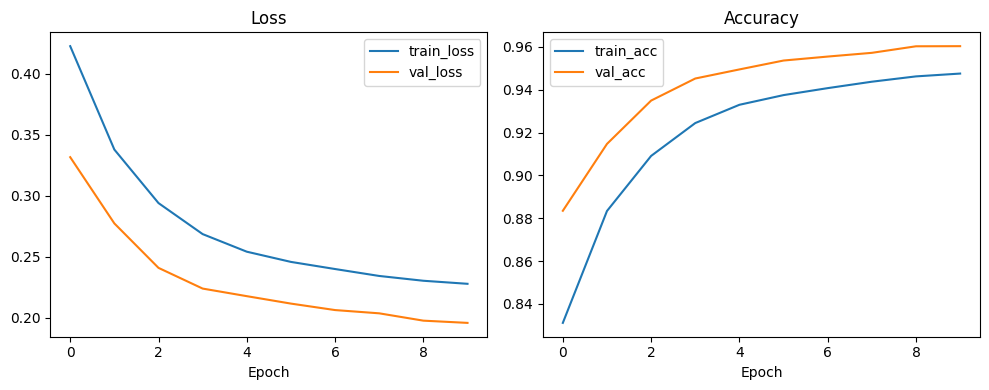

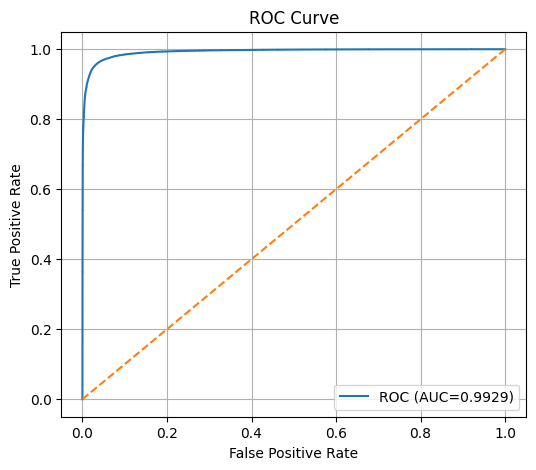

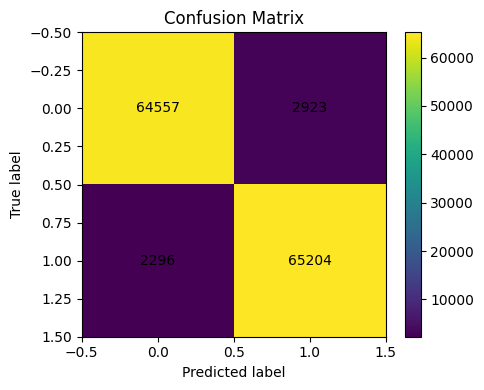

Saved tokenizer -> tokenizer_chars.json
Best model saved as 'best_lstm_dga.h5' (if ModelCheckpoint triggered).
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
Sample predictions: [('google.com', 0.030917905, 0), ('ajk3k2j1k2jk1.asdf', 0.97693366, 1), ('example.org', 0.059499063, 0), ('qwertyuioplkjhgfdsa', 0.9697585, 1)]


In [10]:
# 10. Visualizations (matplotlib only)
# 10.1 Loss & Accuracy curves


plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='train_loss')
plt.plot(history.history['val_loss'], label='val_loss')
plt.title('Loss')
plt.xlabel('Epoch')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label='train_acc')
plt.plot(history.history['val_accuracy'], label='val_acc')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.legend()
plt.tight_layout()
plt.savefig('training_curves.png')
plt.show()

# 10.2 ROC curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f'ROC (AUC={roc_auc:.4f})')
plt.plot([0,1], [0,1], linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.grid(True)
plt.savefig('roc_curve.png')
plt.show()

# 10.3 Confusion matrix as annotated image (no seaborn)
plt.figure(figsize=(5,4))
plt.imshow(cm, interpolation='nearest')
plt.title('Confusion Matrix')
plt.xlabel('Predicted label')
plt.ylabel('True label')
for (i, j), val in np.ndenumerate(cm):
    plt.text(j, i, int(val), ha='center', va='center')
plt.colorbar()
plt.tight_layout()
plt.savefig('confusion_matrix.png')
plt.show()


# 11. Save tokenizer for later use
import json
token_json = tokenizer.to_json()
with open('tokenizer_chars.json', 'w', encoding='utf-8') as f:
    f.write(token_json)
print("Saved tokenizer -> tokenizer_chars.json")
print("Best model saved as 'best_lstm_dga.h5' (if ModelCheckpoint triggered).")

# 12. Example: predict on new samples
def predict_domains(domains, model, tokenizer, maxlen=max_chars, thresh=0.5):
    seq = tokenizer.texts_to_sequences([d.lower().strip() for d in domains])
    seq_p = pad_sequences(seq, maxlen=maxlen, padding='post', truncating='post')
    probs = model.predict(seq_p).ravel()
    return list(zip(domains, probs, (probs >= thresh).astype(int)))

sample_domains = ['google.com', 'ajk3k2j1k2jk1.asdf', 'example.org', 'qwertyuioplkjhgfdsa']
print("Sample predictions:", predict_domains(sample_domains, model, tokenizer))